# 03 · Fraud model: alert budget, cost threshold and drift

**Summary.** The published fraud champion reproduces exactly on the forward-in-time test: PR AUC 0.742, ROC AUC 0.979,
and reviewing the riskiest 0.1% of transactions catches 76.5% of fraud at 83.9% precision. A tuned, unweighted
LightGBM challenger ranks better overall (PR AUC 0.790; paired difference +0.048, 95% CI +0.009 to +0.090) and is
calibrated without correction. At the 0.1% budget, though, it catches the same 104 of 136 frauds, so it is recommended
after a shadow period, not as an immediate switch. Class weighting does not improve ranking; it only inflates the
probabilities (the weighted champion expects 436 frauds where 136 occur). Under stated cost assumptions (EUR 5 per alert;
amount + EUR 20 avoided per fraud caught), net value peaks at 0.15% reviewed. Across the sensitivity grid the optimum
stays at 0.12-0.30%, so the report's 0.1% budget is close to optimal. The V3 step change at midnight trips every PSI
alarm but does not degrade the model (training on day 1 only gives the same PR AUC), so monitoring pairs drift checks
with outcome checks.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "4")      # other projects share this laptop: cap OpenMP/BLAS threads
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

import time
import lightgbm as lgb
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
T0 = time.perf_counter()

## 1. The decision

Every transaction gets a fraud score at authorisation. A fixed team of analysts can review a small share of them, so the
real question is not "is this fraud?" but **"which k% of transactions should the team look at?"**. The metrics follow
from that: recall and precision at a fixed review share, and the money saved net of review cost. ROC AUC is reported
for completeness, but with 1 fraud per 580 transactions it says little about the top of the queue.

## 2. The ETL's forward-in-time split, and parity

Train on the first ~31.4 hours (Time < 113,000 s), test on the following ~16.6 hours. No row from the test window is
used for training, tuning or feature choices.

In [2]:
fr = F.load_fraud(ROOT)
Xf, yf = F.fraud_features(fr), fr["Class"].to_numpy()
tr_m, te_m = F.fraud_split(fr)
Xtr, Xte, ytr, yte = Xf[tr_m], Xf[te_m], yf[tr_m], yf[te_m]
amt_te, time_tr = fr.loc[te_m, "Amount"].to_numpy(), fr.loc[tr_m, "Time"].to_numpy()
pub = pd.read_csv(ROOT / "data" / "model_metrics.csv").set_index("Metric")["Value"]
print(f"train: {tr_m.sum():,} transactions, {ytr.sum()} frauds ({ytr.mean():.3%}) | test: {te_m.sum():,} transactions, {yte.sum()} frauds ({yte.mean():.3%})")

train: 159,847 transactions, 356 frauds (0.223%) | test: 124,960 transactions, 136 frauds (0.109%)


In [3]:
t = time.perf_counter()
champ = HistGradientBoostingClassifier(**F.ETL_FRAUD_GBM).fit(Xtr, ytr)
p_champ = champ.predict_proba(Xte)[:, 1]
fit_s = time.perf_counter() - t
rm = F.review_metrics(yte, p_champ)
rows = {"test transactions": (pub["fraud_test_txns"], len(yte)), "test frauds": (pub["fraud_test_frauds"], yte.sum()),
        "test hours": (pub["fraud_test_hours"], round((fr["Time"].max() - F.FRAUD_CUT) / 3600, 1)),
        "PR AUC": (pub["fraud_pr_auc"], average_precision_score(yte, p_champ)), "ROC AUC": (pub["fraud_roc_auc"], roc_auc_score(yte, p_champ))}
for pct in F.REVIEW_PCTS:
    rows[f"recall, top {pct}%"] = (pub[f"fraud_recall_at_{pct}pct"], rm.loc[pct, "recall"])
    rows[f"precision, top {pct}%"] = (pub[f"fraud_precision_at_{pct}pct"], rm.loc[pct, "precision"])
parity = pd.DataFrame(rows, index=["published", "reproduced"]).T
parity["difference"] = parity["reproduced"] - parity["published"]
assert (parity.loc[["PR AUC", "ROC AUC"], "difference"].abs() < 0.005).all()
assert (parity.filter(like="top", axis=0)["difference"].abs() < 0.01).all()
print(f"Champion fit in {fit_s:.0f} s; early stopping kept {champ.n_iter_} of {F.ETL_FRAUD_GBM['max_iter']} iterations")
parity

Champion fit in 28 s; early stopping kept 78 of 400 iterations


,published,reproduced,difference
test transactions,"124,960.0000","124,960.0000",0.0000
test frauds,136.0000,136.0000,0.0000
test hours,16.6000,16.6000,0.0000
PR AUC,0.7416,0.7416,0.0000
ROC AUC,0.9785,0.9785,0.0000
"recall, top 0.1%",0.7647,0.7647,0.0000
"precision, top 0.1%",0.8387,0.8387,0.0000
"recall, top 0.2%",0.8088,0.8088,0.0000
"precision, top 0.2%",0.4418,0.4418,-0.0000
"recall, top 0.5%",0.8456,0.8456,-0.0000


Every published fraud number reproduces exactly: PR AUC 0.7416, ROC AUC 0.9785, and recall and precision at all four
review budgets. Early stopping kept 78 of the 400 boosting iterations.

## 3. Candidates

| Candidate | Why |
|---|---|
| **Rule: amount** | The rule a business user would try first: review the largest payments. |
| **Rule: best single component** | Rank by the one feature with the highest training AUC (picked and oriented on training data). |
| **Logistic regression** | Standardised inputs, L2. The interpretable baseline. |
| **HistGB champion (ETL)** | Published model: fraud weighted 20x. |
| **HistGB, no class weight** | Same model, unweighted: does the weighting help ranking, or only shift probabilities? |
| **LightGBM (challenger)** | Tuned with Optuna on time-ordered folds inside the training window, average precision as the objective. Then refitted with `scale_pos_weight` of 1, 20 and the full class ratio. |

Validation folds respect time: fold 1 trains on hours 0-16.7 and validates on 16.7-24; fold 2 trains on 0-24 and
validates on 24-31.4. Each validation fold holds 70-80 frauds, so fold scores are noisy and only large gaps count.

In [4]:
folds = [(np.where(time_tr < a)[0], np.where((time_tr >= a) & (time_tr < b))[0]) for a, b in [(60_000, 86_400), (86_400, F.FRAUD_CUT)]]
print("validation frauds per fold:", [int(ytr[v].sum()) for _, v in folds])
tcv = select.PredefinedSplits(folds)
best, study = select.tune_lgbm(Xtr, ytr, tcv, n_trials=12, timeout=300, scoring="average_precision", seed=SEED)   # fixed trial count: same result on a busy or idle machine
print(f"{len(study.trials)} trials, best time-ordered CV average precision {study.best_value:.4f}")
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.items()}

validation frauds per fold: [78, 75]


12 trials, best time-ordered CV average precision 0.8223


{'subsample_freq': 1,
 'random_state': 42,
 'verbose': -1,
 'n_jobs': 4,
 'n_estimators': 400,
 'learning_rate': 0.0352,
 'num_leaves': 30,
 'min_child_samples': 30,
 'subsample': 0.9209,
 'colsample_bytree': 0.5373,
 'reg_lambda': 17.5643}

In [5]:
ratio = (ytr == 0).sum() / ytr.sum()
models = {
    "Rule: amount": F.OneFeatureRule("Amount"),
    "Rule: best single component": F.OneFeatureRule(),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)),
    "HistGB champion (ETL)": HistGradientBoostingClassifier(**F.ETL_FRAUD_GBM),
    "HistGB, no class weight": HistGradientBoostingClassifier(**{k: v for k, v in F.ETL_FRAUD_GBM.items() if k != "class_weight"}),
    "LightGBM (challenger)": lgb.LGBMClassifier(**best),
    "LightGBM, weight 20": lgb.LGBMClassifier(**best, scale_pos_weight=20),
    f"LightGBM, weight {ratio:.0f} (balanced)": lgb.LGBMClassifier(**best, scale_pos_weight=ratio),
}
cvt = select.cv_compare({k: v for k, v in models.items() if k != "LightGBM, weight 20"}, Xtr, ytr, tcv, scoring=("average_precision", "roc_auc"))
cvt

,fit_seconds,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
model,,,,,
Rule: amount,0.0700,0.0080,0.0046,0.5031,0.0226
Rule: best single component,0.9500,0.6444,0.1057,0.9381,0.0049
Logistic regression,0.3000,0.7115,0.0565,0.9506,0.0178
HistGB champion (ETL),11.1800,0.7990,0.0420,0.9665,0.0215
"HistGB, no class weight",2.3500,0.8226,0.0340,0.9754,0.0173
LightGBM (challenger),4.3300,0.8223,0.0350,0.9768,0.0173
"LightGBM, weight 448 (balanced)",5.9400,0.8125,0.0479,0.9570,0.0128


* **The amount rule is no better than chance** (AUC 0.50): fraud is not where the big payments are.
* **One component goes a long way.** V14, chosen on training data, reaches PR AUC 0.64 and AUC 0.94. Logistic regression
  reaches 0.71.
* **Boosting adds 0.09-0.11 PR AUC over logistic.** Within boosting, class weighting does not help ranking: the
  unweighted HistGB (0.823) and unweighted LightGBM (0.822) edge out the 20x-weighted champion (0.799). The fully
  balanced weight is the weakest LightGBM (0.813, with ROC AUC down to 0.957). Weighting changes the probabilities, not
  the order, and with trees the order is what the queue uses.
* Fold standard deviations are 0.03-0.05 on 75-78 frauds per fold, so only gaps above about 0.05 deserve weight.

## 4. The test window: precision-recall first, with uncertainty

In [6]:
fitted = {n: (champ if n == "HistGB champion (ETL)" else m.fit(Xtr, ytr)) for n, m in models.items()}
preds = {n: m.predict_proba(Xte)[:, 1] for n, m in fitted.items()}
print("Best single component chosen on training data:", fitted["Rule: best single component"].feature_)
mt = evaluate.metrics_table(yte, preds, n_boot=150, seed=SEED)
budget = pd.DataFrame({n: F.review_metrics(yte, p).stack() for n, p in preds.items()}).T
budget.columns = [f"{m} @ {pct}%" for pct, m in budget.columns]
mt.join(budget[[c for c in budget.columns if c.startswith(("recall @ 0.1", "precision @ 0.1", "recall @ 0.5"))]])[
    ["PR AUC", "PR AUC 95% CI", "AUC", "AUC 95% CI", "recall @ 0.1%", "precision @ 0.1%", "recall @ 0.5%"]]

Best single component chosen on training data: V14


,PR AUC,PR AUC 95% CI,AUC,AUC 95% CI,recall @ 0.1%,precision @ 0.1%,recall @ 0.5%
model,,,,,,,
Rule: amount,0.0036,0.002 - 0.006,0.5617,0.488 - 0.628,0.0074,0.0081,0.0294
Rule: best single component,0.5820,0.505 - 0.681,0.9360,0.899 - 0.967,0.5588,0.6129,0.7868
Logistic regression,0.6380,0.550 - 0.723,0.9721,0.957 - 0.988,0.6029,0.6613,0.8382
HistGB champion (ETL),0.7416,0.652 - 0.825,0.9785,0.966 - 0.990,0.7647,0.8387,0.8456
"HistGB, no class weight",0.7628,0.691 - 0.828,0.9786,0.966 - 0.989,0.7353,0.8065,0.8456
LightGBM (challenger),0.7897,0.716 - 0.854,0.9849,0.977 - 0.992,0.7647,0.8387,0.8382
"LightGBM, weight 20",0.7762,0.705 - 0.839,0.9822,0.973 - 0.990,0.7279,0.7984,0.8603
"LightGBM, weight 448 (balanced)",0.7784,0.701 - 0.844,0.9571,0.931 - 0.977,0.7353,0.8065,0.8235


In [7]:
def paired_bootstrap(y, a, b, fn, n=300, seed=SEED):
    """Paired, class-stratified bootstrap of fn(y, a) - fn(y, b) on the same rows."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    d = np.array([fn(y[ix], a[ix]) - fn(y[ix], b[ix]) for ix in
                  (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(n))])
    return {"delta": fn(y, a) - fn(y, b), "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5), "p_one_sided": float((d <= 0).mean())}


def recall_at(share):
    def fn(y, s):
        k = max(1, int(round(share * len(y))))
        return y[np.argpartition(-s, k - 1)[:k]].sum() / y.sum()
    return fn


CH, CL = "HistGB champion (ETL)", "LightGBM (challenger)"
tests = pd.DataFrame({
    "PR AUC: challenger - champion": paired_bootstrap(yte, preds[CL], preds[CH], average_precision_score),
    "Recall at 0.1%: challenger - champion": paired_bootstrap(yte, preds[CL], preds[CH], recall_at(0.001)),
    "PR AUC: champion - logistic": paired_bootstrap(yte, preds[CH], preds["Logistic regression"], average_precision_score),
    "PR AUC: champion - unweighted HistGB": paired_bootstrap(yte, preds[CH], preds["HistGB, no class weight"], average_precision_score),
}).T
ci_rec = {n: evaluate.bootstrap_ci(yte, preds[n], recall_at(0.001), n=300, seed=SEED) for n in (CH, CL, "Logistic regression")}
print("Recall in the top 0.1% with 95% bootstrap CI:", {n: f"{v[0]:.3f} ({v[1]:.3f}-{v[2]:.3f})" for n, v in ci_rec.items()})
tests

Recall in the top 0.1% with 95% bootstrap CI: {'HistGB champion (ETL)': '0.765 (0.695-0.809)', 'LightGBM (challenger)': '0.765 (0.699-0.831)', 'Logistic regression': '0.610 (0.540-0.676)'}


,delta,ci_low,ci_high,p_one_sided
PR AUC: challenger - champion,0.0481,0.0091,0.0899,0.0000
Recall at 0.1%: challenger - champion,0.0000,-0.0221,0.0588,0.3400
PR AUC: champion - logistic,0.1036,0.0360,0.1640,0.0000
PR AUC: champion - unweighted HistGB,-0.0212,-0.0653,0.0229,0.7900


* **The tuned, unweighted LightGBM has the best PR AUC on the test window**: 0.790 against 0.742 for the champion. The
  paired bootstrap difference is +0.048 (95% CI +0.009 to +0.090; none of 300 resamples at or below zero), a real improvement in ranking
  overall.
* **At the report's operating point it changes nothing.** Both catch 104 of 136 frauds in the top 0.1% (recall 0.765;
  challenger minus champion 0.000, CI -0.022 to +0.059). The gain sits at the very top of the queue and deeper down.
* The champion beats logistic regression by 0.104 PR AUC (CI 0.036 to 0.164). Weighted vs unweighted HistGB cannot be
  told apart (difference -0.021, CI -0.065 to +0.023).
* ROC AUC is 0.96-0.98 for every model except the amount rule, so it cannot separate the candidates that matter.

## 5. The alert-budget curve

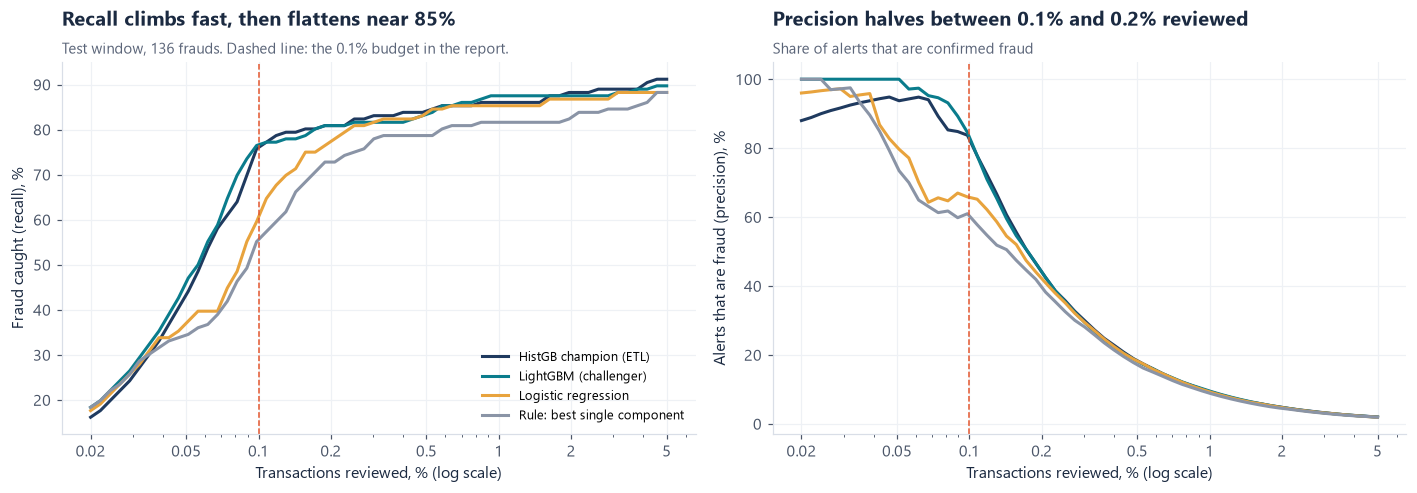

,alerts,frauds_caught,recall,precision,alerts_per_hour
review_pct,,,,,
0.1000,124,104,0.7647,0.8387,7.4659
0.2000,249,110,0.8088,0.4418,14.9920
0.5000,624,115,0.8456,0.1843,37.5702
1.0000,1249,117,0.8603,0.0937,75.2007


In [8]:
shares = np.geomspace(0.0002, 0.05, 60)
def curve(y, s):
    order = np.argsort(-s, kind="stable")
    tp = np.cumsum(y[order])
    k = np.maximum(1, np.round(shares * len(y)).astype(int))
    return tp[k - 1] / y.sum(), tp[k - 1] / k
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
for n, c in [(CH, PALETTE["navy"]), (CL, PALETTE["teal"]), ("Logistic regression", PALETTE["amber"]), ("Rule: best single component", PALETTE["grey"])]:
    rec, prec = curve(yte, preds[n])
    a1.plot(shares * 100, rec * 100, color=c, label=n)
    a2.plot(shares * 100, prec * 100, color=c, label=n)
for ax in (a1, a2):
    ax.set_xscale("log"); ax.set_xticks([0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5], ["0.02", "0.05", "0.1", "0.2", "0.5", "1", "2", "5"])
    ax.axvline(0.1, color=PALETTE["coral"], lw=1, ls="--"); ax.set_xlabel("Transactions reviewed, % (log scale)")
a1.set_ylabel("Fraud caught (recall), %"); a2.set_ylabel("Alerts that are fraud (precision), %")
a1.legend(loc="lower right", fontsize=8.5)
headline(a1, "Recall climbs fast, then flattens near 85%", "Test window, 136 frauds. Dashed line: the 0.1% budget in the report.")
headline(a2, "Precision halves between 0.1% and 0.2% reviewed", "Share of alerts that are confirmed fraud")
fig.tight_layout(); _ = savefig(fig, "03-alert-budget", FIG); plt.show()
rm.assign(alerts_per_hour=rm["alerts"] / ((fr["Time"].max() - F.FRAUD_CUT) / 3600))

Recall rises steeply to the 0.1% mark: 76% of fraud with 124 alerts, about 7.5 an hour, which is one analyst. Then it
flattens. Doubling the budget to 0.2% adds 6 frauds (81%) while precision halves from 84% to 44%. Going to 1% (75
alerts an hour) adds 13 frauds in total. The last ~14% of fraud looks like genuine traffic to every model here; finding
it needs features this dataset does not have (card history, device, merchant).

## 6. A cost-based review share

The report lets the user pick the review share. Here the share is chosen on money instead, under stated assumptions:

| Assumption | Base value | Why |
|---|---|---|
| Analyst cost per alert | EUR 5 | About 6 minutes of a fraud analyst at EUR 50 per hour, fully loaded |
| Loss avoided per fraud caught | the transaction amount + EUR 20 | The amount is blocked before settlement; EUR 20 covers chargeback handling and card reissue |
| Cost of a missed fraud | nothing extra | The loss is simply not avoided |
| Customer friction on a false alert | not costed | Covered by the analyst cost; a stricter view raises the per-alert cost (see sensitivity) |

These are planning assumptions, not data. The sensitivity table below shows how the answer moves when they do.

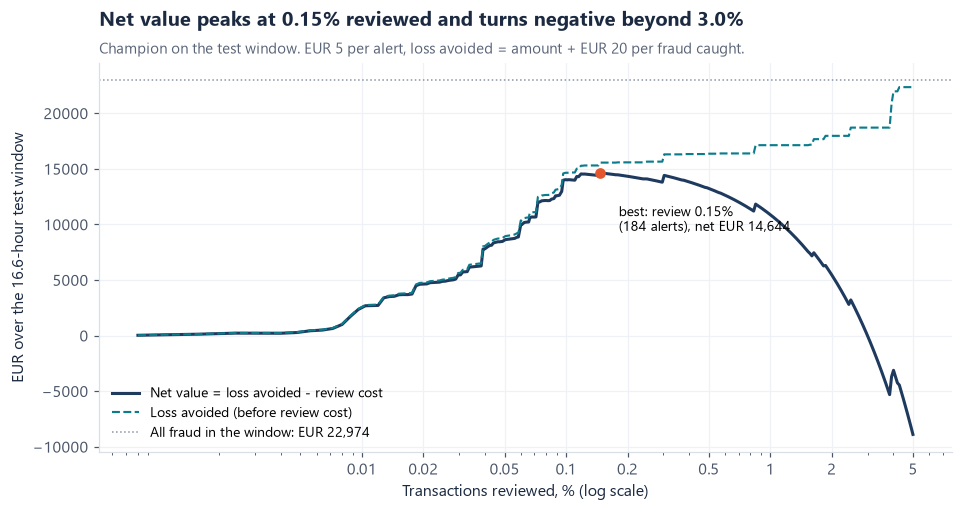

Net EUR at 0.1% (124 alerts): 14,028 | at 0.2% (249 alerts): 14,336 | at the optimum (184 alerts): 14,644 | negative beyond 3.0% reviewed


In [9]:
grid = np.unique(np.round(np.geomspace(1, 0.05 * len(yte), 400)).astype(int))
def value_curve(s, cost_alert=5.0, per_fraud=20.0):
    order = np.argsort(-s, kind="stable")
    yy, aa = yte[order], amt_te[order]
    saved = np.cumsum(aa * yy) + per_fraud * np.cumsum(yy)
    return saved[grid - 1] - cost_alert * grid, saved[grid - 1]
net, saved = value_curve(preds[CH])
i_best = int(np.argmax(net))
k01 = int(rm.loc[0.1, "alerts"])
net01 = value_curve(preds[CH])[0][np.searchsorted(grid, k01)]
fraud_total = amt_te[yte == 1].sum() + 20 * yte.sum()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(grid / len(yte) * 100, net, color=PALETTE["navy"], label="Net value = loss avoided - review cost")
ax.plot(grid / len(yte) * 100, saved, color=PALETTE["teal"], ls="--", lw=1.4, label="Loss avoided (before review cost)")
ax.axhline(fraud_total, color=PALETTE["grey"], lw=1, ls=":", label=f"All fraud in the window: EUR {fraud_total:,.0f}")
ax.scatter([grid[i_best] / len(yte) * 100], [net[i_best]], color=PALETTE["coral"], zorder=3)
ax.annotate(f"best: review {grid[i_best] / len(yte):.2%}\n({grid[i_best]} alerts), net EUR {net[i_best]:,.0f}", (grid[i_best] / len(yte) * 100, net[i_best]),
            xytext=(12, -38), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5], ["0.01", "0.02", "0.05", "0.1", "0.2", "0.5", "1", "2", "5"])
ax.set(xlabel="Transactions reviewed, % (log scale)", ylabel="EUR over the 16.6-hour test window")
ax.legend(loc="lower left", fontsize=9)
zero = grid[np.where((net < 0) & (np.arange(len(grid)) > i_best))[0][0]] / len(yte)
headline(ax, f"Net value peaks at {grid[i_best] / len(yte):.2%} reviewed and turns negative beyond {zero:.1%}",
         "Champion on the test window. EUR 5 per alert, loss avoided = amount + EUR 20 per fraud caught.")
_ = savefig(fig, "03-cost-threshold", FIG); plt.show()
k02 = int(F.review_metrics(yte, preds[CH], pcts=(0.2,)).loc[0.2, "alerts"])
print(f"Net EUR at 0.1% ({k01} alerts): {net01:,.0f} | at 0.2% ({k02} alerts): {net[np.searchsorted(grid, k02)]:,.0f} | "
      f"at the optimum ({grid[i_best]} alerts): {net[i_best]:,.0f} | negative beyond {zero:.1%} reviewed")

In [10]:
sens = []
for c in (2, 5, 10, 20):
    for pf in (0, 20, 50):
        n_, _ = value_curve(preds[CH], c, pf)
        j = int(np.argmax(n_))
        sens.append({"cost per alert (EUR)": c, "handling cost per fraud (EUR)": pf, "best review share": grid[j] / len(yte),
                     "alerts": int(grid[j]), "net value at best (EUR)": n_[j], "net value at 0.1% (EUR)": n_[np.searchsorted(grid, k01)]})
sens = pd.DataFrame(sens)
sens.pivot(index="cost per alert (EUR)", columns="handling cost per fraud (EUR)", values="best review share").map(lambda v: f"{v:.2%}")

handling cost per fraud (EUR),0,20,50
cost per alert (EUR),,,
2,0.30%,0.30%,0.30%
5,0.15%,0.15%,0.15%
10,0.12%,0.12%,0.12%
20,0.12%,0.12%,0.12%


* At EUR 5 per alert the value curve peaks at 0.15% reviewed (184 alerts): EUR 14,644 net over the 16.6-hour window,
  against EUR 14,028 at the report's 0.1%. The top of the curve is flat, so the published budget gives up about 4%.
* Across the sensitivity grid the best share stays between 0.12% and 0.30%. The handling cost per fraud does not move
  it, because so few frauds sit beyond the optimum. Only a cheap review (EUR 2 per alert) justifies going to 0.3%.
* Past about 3% reviewed, analysts cost more than the fraud they find.
* So the report's 0.1% budget is a defensible default. The money case for a larger team is weak unless new features
  lift recall in the flat part of the curve.

## 7. Calibration on rare events

Two things distort the champion's probabilities: the 20x class weight inflates the fraud odds by about 20, and the fraud
rate in the test window (0.11%) is half the training rate (0.22%). The weight has a closed-form fix: divide the odds
by 20. The base-rate shift can only be fixed once labels for the new period arrive.

In [11]:
p_corr = F.prior_correct(p_champ, 20)
p_lgb = preds[CL]
cal_sum = pd.DataFrame({
    "expected frauds (sum of p)": [p_champ.sum(), p_corr.sum(), p_lgb.sum()],
    "observed frauds": [yte.sum()] * 3,
    "Brier": [evaluate.binary_metrics(yte, p)["brier"] for p in (p_champ, p_corr, p_lgb)],
    "log loss": [evaluate.binary_metrics(yte, p)["log_loss"] for p in (p_champ, p_corr, p_lgb)],
    "PR AUC": [average_precision_score(yte, p) for p in (p_champ, p_corr, p_lgb)]},
    index=["Champion, raw (weighted 20x)", "Champion, weight undone", "LightGBM challenger (unweighted)"])
cal_sum

,expected frauds (sum of p),observed frauds,Brier,log loss,PR AUC
"Champion, raw (weighted 20x)",436.3563,136,0.0005,0.0042,0.7416
"Champion, weight undone",86.7443,136,0.0005,0.0026,0.7416
LightGBM challenger (unweighted),145.8920,136,0.0003,0.0021,0.7897


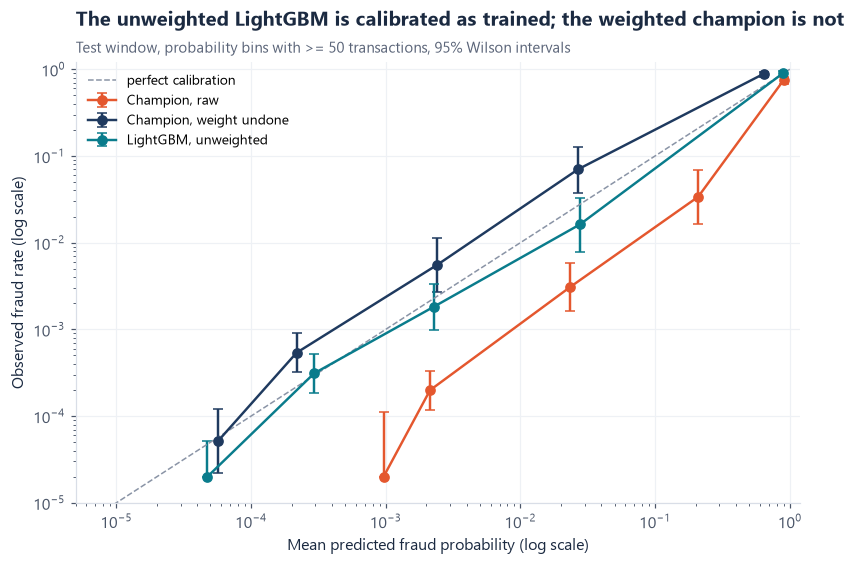

In [12]:
edges = np.array([0, 1e-4, 1e-3, 1e-2, 0.1, 0.5, 1.0001])
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for p, lab, c in [(p_champ, "Champion, raw", PALETTE["coral"]), (p_corr, "Champion, weight undone", PALETTE["navy"]), (p_lgb, "LightGBM, unweighted", PALETTE["teal"])]:
    b = np.digitize(p, edges)
    g = pd.DataFrame({"b": b, "y": yte, "p": p}).groupby("b").agg(n=("y", "size"), k=("y", "sum"), p=("p", "mean"))
    g = g[g["n"] >= 50]
    lo, hi = eda.wilson(g["k"], g["n"])
    obs = (g["k"] / g["n"]).clip(lower=2e-5)
    ax.errorbar(g["p"], obs, yerr=[obs - np.clip(lo, 2e-5, None), np.clip(hi, 2e-5, None) - obs], marker="o", color=c, label=lab, capsize=3, lw=1.6)
ax.plot([1e-6, 1], [1e-6, 1], ls="--", color=PALETTE["grey"], lw=1, label="perfect calibration")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(5e-6, 1.2); ax.set_ylim(1e-5, 1.2)
ax.set(xlabel="Mean predicted fraud probability (log scale)", ylabel="Observed fraud rate (log scale)")
ax.legend(loc="upper left", fontsize=9)
headline(ax, "The unweighted LightGBM is calibrated as trained; the weighted champion is not",
         "Test window, probability bins with >= 50 transactions, 95% Wilson intervals")
_ = savefig(fig, "03-calibration", FIG); plt.show()

* **The raw champion predicts 436 frauds in a window that has 136.** The 20x weight inflates every probability.
* **Dividing the odds by 20 overshoots the other way** (87 expected). The weight interacts with early stopping and
  regularisation, so the closed-form correction is only approximate, and the fraud rate also halved between the windows.
* **The unweighted LightGBM expects 146 frauds against 136 observed, with no correction**, and its reliability curve
  follows the diagonal across four orders of magnitude.
* **Practical point:** if the probabilities feed anything (fraud-loss forecasts, or a queue ranked by p x amount), train
  unweighted or recalibrate on a recent labelled window. For a pure top-k queue, calibration does not matter.

## 8. What drives an alert, and what can honestly be said about it

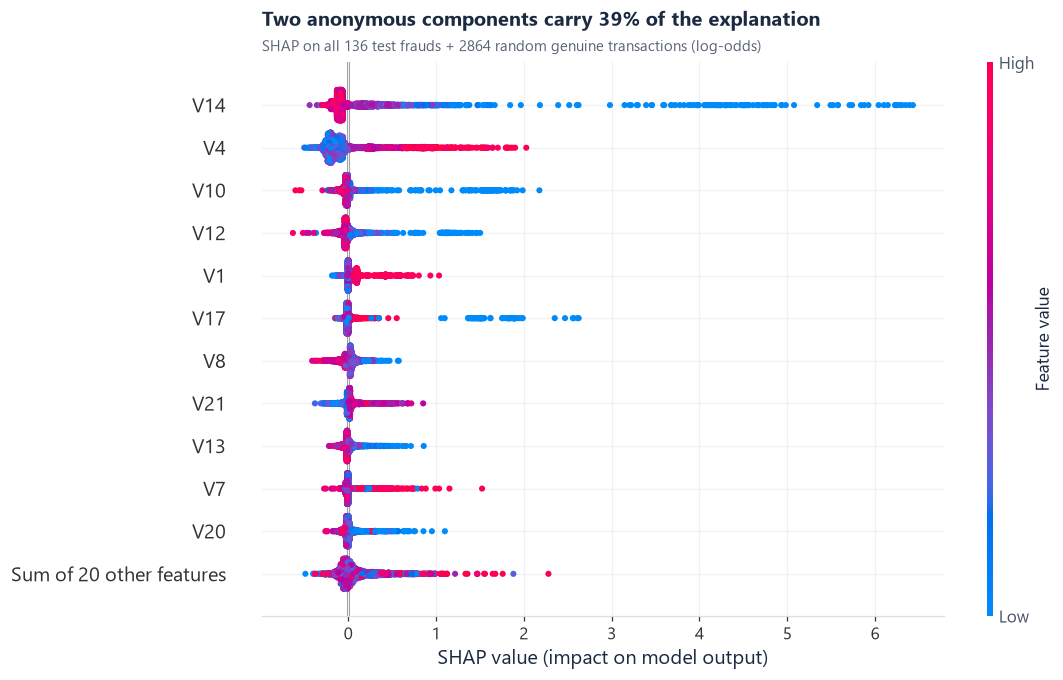

In [13]:
rng = np.random.default_rng(SEED)
idx = np.r_[np.where(yte == 1)[0], rng.choice(np.where(yte == 0)[0], 3000 - int(yte.sum()), replace=False)]
Xs = Xte.iloc[idx]
e = explain.shap_explanation(champ, Xs, sample=3000, seed=SEED)
fig = explain.plot_shap_beeswarm(e, max_display=12, title="Two anonymous components carry 39% of the explanation",
                                 subtitle=f"SHAP on all {int(yte.sum())} test frauds + {3000 - int(yte.sum())} random genuine transactions (log-odds)")
_ = savefig(fig, "03-shap-beeswarm", FIG); plt.show()

In [14]:
imp = explain.shap_importance(e)
pos_s, neg_s = np.where(yte == 1)[0], rng.choice(np.where(yte == 0)[0], 20_000, replace=False)
sub = np.r_[pos_s, neg_s]
perm = explain.permutation_table(champ, Xte.iloc[sub], yte[sub], scoring="average_precision", n_repeats=3, seed=SEED)
both = imp[["share"]].join(perm[["drop_mean"]]).rename(columns={"share": "SHAP share", "drop_mean": "PR AUC drop when shuffled"})
print(f"Top 4 components carry {imp['share'].head(4).sum():.0%} of mean |SHAP|; Amount {imp.loc['Amount', 'share'] + imp.loc['log_amount', 'share']:.1%}, hour {imp.loc['hour', 'share']:.1%}")
print(f"Rank agreement SHAP vs permutation (Spearman): {both['SHAP share'].rank().corr(both['PR AUC drop when shuffled'].rank()):.2f}")
both.head(10)

Top 4 components carry 51% of mean |SHAP|; Amount 2.0%, hour 1.9%
Rank agreement SHAP vs permutation (Spearman): 0.44


,SHAP share,PR AUC drop when shuffled
feature,,
V14,0.2342,0.2190
V4,0.1567,0.0345
V10,0.0585,-0.0158
V12,0.0567,0.0417
V1,0.0465,0.0023
V17,0.0462,-0.0015
V8,0.0421,0.0041
V21,0.0362,0.0062
V13,0.0296,0.0062


* V14 and V4 carry 39% of mean |SHAP| between them; the top four components (V14, V4, V10, V12) carry 51%. Low V14 and
  high V4 push towards fraud, matching the distributions in notebook 01.
* Amount and hour of day, the only named inputs, carry about 2% each.
* Permutation importance agrees on the top feature (V14) but not much beyond it (rank correlation 0.44). With 136 frauds,
  shuffling one component moves PR AUC by less than the noise, and correlated components stand in for each other.
* **What can honestly be said:** which components drive alerts, in which direction, and whether that mix is stable
  over time. **What cannot:** a business reason. "Low V14" means nothing to an analyst or a customer. Here SHAP is a
  monitoring tool (has the driver mix changed?) and a way to group alerts into recurring patterns, not an explanation.
  With the original fields (merchant category, country, channel, card age), the same SHAP pipeline would produce
  analyst-facing reason codes.

## 9. Drift and retraining cadence

Notebook 01 found a step change at midnight: component V3 flips sign on day 2. The ETL's training window ends 7.4 hours
into day 2, so the champion has seen some of the new regime. How much does that matter? Refit the same model on day 1
only and score the same test window.

In [15]:
d1 = fr.loc[tr_m, "Time"].to_numpy() < 86_400
m_d1 = HistGradientBoostingClassifier(**F.ETL_FRAUD_GBM).fit(Xtr[d1], ytr[d1])
p_d1 = m_d1.predict_proba(Xte)[:, 1]
no_v3 = [c for c in Xtr.columns if c != "V3"]
m_nov3 = HistGradientBoostingClassifier(**F.ETL_FRAUD_GBM).fit(Xtr[d1][no_v3], ytr[d1])
p_nov3 = m_nov3.predict_proba(Xte[no_v3])[:, 1]
drift = pd.DataFrame({n: {"training rows": r, "training frauds": f_, "PR AUC": average_precision_score(yte, p), "recall @ 0.1%": F.review_metrics(yte, p).loc[0.1, "recall"],
                          "precision @ 0.1%": F.review_metrics(yte, p).loc[0.1, "precision"]}
                      for n, r, f_, p in [("ETL window (31.4 h, incl. 7.4 h of day 2)", len(ytr), ytr.sum(), p_champ),
                                          ("Day 1 only (24 h)", d1.sum(), ytr[d1].sum(), p_d1),
                                          ("Day 1 only, V3 dropped", d1.sum(), ytr[d1].sum(), p_nov3)]}).T
drift

,training rows,training frauds,PR AUC,recall @ 0.1%,precision @ 0.1%
"ETL window (31.4 h, incl. 7.4 h of day 2)","159,847.0000",356.0000,0.7416,0.7647,0.8387
Day 1 only (24 h),"144,786.0000",281.0000,0.7615,0.7500,0.8226
"Day 1 only, V3 dropped","144,786.0000",281.0000,0.7424,0.7426,0.8145


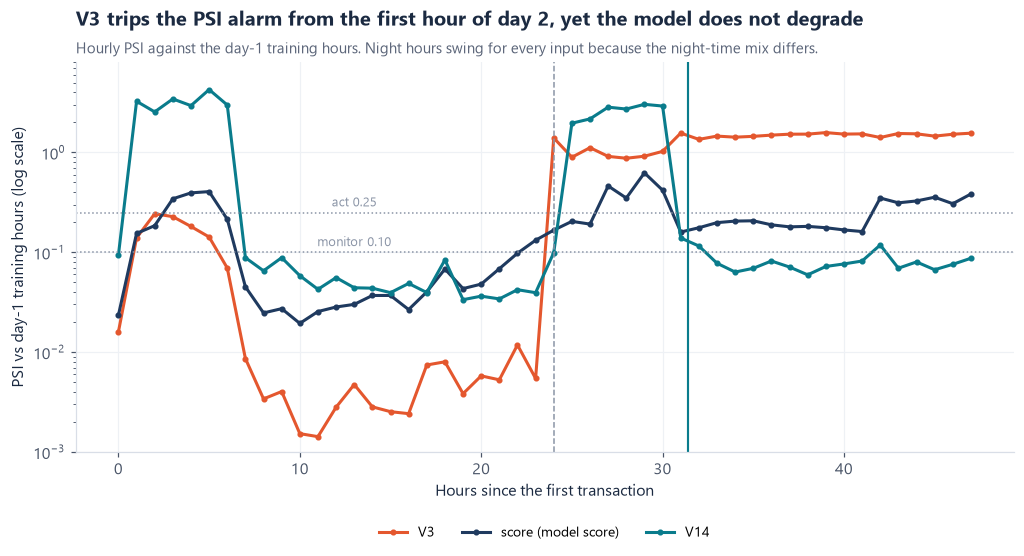

,transactions,frauds,PSI score,PSI V3,PSI V14
hour,,,,,
3,1821,13,0.3431,0.2272,3.4335
12,7732,9,0.0283,0.0028,0.0557
20,8980,8,0.0479,0.0058,0.0363
25,2003,8,0.2038,0.8946,1.9612
30,2270,6,0.4184,1.0239,2.9139
33,7960,1,0.1979,1.4571,0.0776
40,8667,8,0.1673,1.5258,0.0764
46,6464,6,0.3064,1.5208,0.0757


In [16]:
habs = (fr["Time"] // 3600).astype(int).to_numpy()
s_all = champ.predict_proba(Xf)[:, 1]
ref = tr_m & (fr["Time"].to_numpy() < 86_400)
mon = []
for h in range(48):
    m = habs == h
    mon.append({"hour": h, "transactions": int(m.sum()), "frauds": int(yf[m].sum()),
                "PSI score": eda.psi(s_all[ref], s_all[m]), "PSI V3": eda.psi(fr.loc[ref, "V3"], fr.loc[m, "V3"]),
                "PSI V14": eda.psi(fr.loc[ref, "V14"], fr.loc[m, "V14"])})
mon = pd.DataFrame(mon).set_index("hour")
fig, ax = plt.subplots(figsize=(11, 4.6))
for c, colr in [("PSI V3", PALETTE["coral"]), ("PSI score", PALETTE["navy"]), ("PSI V14", PALETTE["teal"])]:
    ax.plot(mon.index, mon[c], marker="o", ms=3, color=colr, label=c.replace("PSI ", "") + (" (model score)" if c == "PSI score" else ""))
for th, lab in [(0.1, "monitor 0.10"), (0.25, "act 0.25")]:
    ax.axhline(th, color=PALETTE["grey"], ls=":", lw=1); ax.text(13, th * 1.08, lab, fontsize=8.5, color=PALETTE["grey"], va="bottom", ha="center")
ax.axvline(24, color=PALETTE["grey"], lw=1, ls="--"); ax.axvline(F.FRAUD_CUT / 3600, color=PALETTE["teal"], lw=1.4)
ax.set_yscale("log"); ax.set_ylim(1e-3, 8); ax.set(xlabel="Hours since the first transaction", ylabel="PSI vs day-1 training hours (log scale)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
headline(ax, "V3 trips the PSI alarm from the first hour of day 2, yet the model does not degrade",
         "Hourly PSI against the day-1 training hours. Night hours swing for every input because the night-time mix differs.")
_ = savefig(fig, "03-drift-monitor", FIG); plt.show()
mon.loc[[3, 12, 20, 25, 30, 33, 40, 46]]

* **The step change does not hurt this model.** Trained on day 1 only, the champion scores PR AUC 0.762 on the test
  window, against 0.742 for the ETL's 31.4-hour window; with a bootstrap interval about +/- 0.08 wide, the two cannot be
  told apart. Dropping V3 as well gives 0.742. The fraud signal lives in components that do not shift (V14, V4, V12),
  and V3 carries little of it.
* **PSI would still raise the alarm.** V3 reads 1.3-1.5 in every hour from the first hour of day 2, and the score's PSI
  sits at 0.2-0.4 through the test window. A retraining trigger based on PSI alone would have retrained for nothing.
* **Night hours swing for every input** (V14 PSI above 2 between 1 and 6 a.m. on both days) because the night-time
  transaction mix differs, not because the world changed. Hourly PSI against an all-day reference is mostly noise;
  compare like-for-like hours.
* **So monitoring pairs drift with outcomes.** PSI says where to look. The precision of the review queue (known within a
  day from analyst decisions) and recall on confirmed fraud (known weeks later) decide whether to retrain.

## 10. Decision, monitoring and limitations

* **Keep the published champion for the report.** Its numbers reproduce exactly, and the 0.1% budget catches 76% of
  fraud at 84% precision.
* **Promote the unweighted LightGBM after a shadow period.** It ranks better overall (PR AUC +0.048, CI +0.009 to +0.090),
  it is calibrated without correction (146 expected vs 136 observed frauds), and it ties the champion at the 0.1% budget,
  so switching cannot make the current queue worse. 136 test frauds is a small sample, so two weeks of shadow scoring on
  live traffic should confirm the gain first.
* **Review budget: 0.1-0.2% of transactions**, about 7-15 alerts an hour at this volume. The value curve peaks at 0.15%
  under the base assumptions and stays between 0.12% and 0.30% under every assumption tested.

**Monitoring plan**

| What | How often | Trigger | Action |
|---|---|---|---|
| PSI of each input and of the score vs the last training window, same clock hours | Daily (hourly PSI is too noisy at night) | > 0.10 monitor, > 0.25 on a top-10 SHAP feature or the score | Investigate; retrain if confirmed |
| Alert volume and precision of the review queue (confirmed fraud / alerts) | Daily | Precision below 50% at the 0.1% budget for 3 days | Retrain; review threshold |
| Recall on confirmed fraud, including fraud found later via chargebacks | Weekly (labels arrive late) | Recall at the budget below 70% | Retrain; look for a new pattern |
| Expected vs observed fraud count (calibration) | Weekly | Ratio outside 0.5-2 | Re-estimate the base-rate correction |
| Champion vs challenger on the same live traffic (shadow scoring) | Continuous | Challenger ahead on PR AUC for 2 weeks with a paired CI above zero | Promote |

**Retraining cadence.** Retrain daily on a rolling window that always includes the most recent complete day. The day-1-only
experiment above shows what is lost by training on stale data; in production, fraud patterns change on the scale of days.

**Proving causal value.** Score everything, but send a random 5% of above-threshold alerts to a "no review" holdout arm.
Comparing fraud losses between reviewed and unreviewed alerts measures the loss actually prevented, rather than
assuming every caught fraud would have succeeded.

**Limitations**

* Two days of 2013 data. Fraud patterns, attack rates and the day-2 regime change cannot be generalised from this.
* The PCA was fitted by the data provider on both days, so the test window is not fully unseen. Results are slightly optimistic.
* No cardholder, merchant or device identifiers, so the velocity and history features that dominate real fraud models are impossible here.
* Labels are taken as final. In practice fraud is confirmed weeks later and some is never reported.
* Amounts are the only money variable; the cost assumptions are illustrative, and the sensitivity table matters more than the point estimate.

**What I would do next**

* Add velocity features (transactions per card in the last hour/day) on a dataset with card IDs.
* Train on a rolling window with time-decayed sample weights and compare against the fixed window.
* Replace the fixed review share with a value-based queue: rank by p x amount and stop where the marginal alert costs more than it saves.

In [17]:
report.update_metrics(METRICS, "03_fraud_model", {
    "parity": {k: {"published": float(r["published"]), "reproduced": float(r["reproduced"])} for k, r in parity.iterrows()},
    "cv": {k: {"pr_auc": float(r["average_precision_mean"]), "pr_auc_sd": float(r["average_precision_std"]), "auc": float(r["roc_auc_mean"])} for k, r in cvt.iterrows()},
    "test": {k: {"pr_auc": float(r["PR AUC"]), "pr_auc_ci": r["PR AUC 95% CI"], "auc": float(r["AUC"]), "auc_ci": r["AUC 95% CI"]} for k, r in mt.iterrows()},
    "recall_at_0.1pct_ci": {k: list(v) for k, v in ci_rec.items()},
    "paired_tests": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in tests.iterrows()},
    "cost_threshold": {"cost_per_alert": 5, "handling_per_fraud": 20, "best_share": grid[i_best] / len(yte), "best_alerts": int(grid[i_best]),
                       "net_at_best": float(net[i_best]), "net_at_0.1pct": float(net01)},
    "calibration": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in cal_sum.iterrows()},
    "drift": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in drift.iterrows()},
    "lgbm_best_params": best,
})
print(f"Notebook runtime: {time.perf_counter() - T0:.0f} s")

Notebook runtime: 460 s
